# Dithering de Floyd-Steinberg para quantização de imagens

**Computação Visual (2026.2)** — Prof. André Kishimoto  
Universidade Presbiteriana Mackenzie — FCI — Ciência da Computação

**Integrantes**
- Luiz Eduardo Bacha dos Santos — RA 10425296
- Guilherme Haddad Borro — RA 10427699

---

Neste tutorial a gente mostra como converter uma imagem para pouquíssimos tons (no limite, só preto e branco) sem perder a sensação de detalhe. O truque é o **dithering por difusão de erro**, e o algoritmo mais conhecido dessa família é o de **Floyd-Steinberg**.

A ideia é seguir este caminho:
1. Entender o que é quantização e por que ela gera erro.
2. Ver como o Floyd-Steinberg espalha esse erro para os vizinhos.
3. Na prática: carregar uma imagem, passar para escala de cinza, aplicar uma limiarização simples e depois o dithering, comparando os resultados.
4. Repetir com diferentes níveis de quantização e discutir vantagens, limitações e artefatos.
5. Estender o método para imagens coloridas, aplicando o dithering em cada canal RGB.

## 1. Teoria

### 1.1 Representação da imagem e quantização

Uma imagem digital em escala de cinza é uma matriz $I(x, y)$ em que cada pixel guarda uma intensidade. No formato mais comum (8 bits), esse valor vai de 0 (preto) a 255 (branco), ou seja, 256 tons possíveis.

**Quantizar** é reduzir essa quantidade de tons. Se queremos só $n$ níveis, os valores permitidos ficam igualmente espaçados entre 0 e 255, com passo

$$\Delta = \frac{255}{n - 1}$$

e cada pixel é trocado pelo nível mais próximo:

$$Q(v) = \Delta \cdot \operatorname{round}\left(\frac{v}{\Delta}\right)$$

Com $n = 2$ isso vira uma **limiarização**: tudo abaixo de um limiar (por volta de 128) vira 0 e o resto vira 255.

### 1.2 O erro de quantização

Toda vez que trocamos $v$ por $Q(v)$ cometemos um erro

$$e = v - Q(v)$$

Na quantização direta esse erro simplesmente é jogado fora, pixel por pixel. O problema é que, numa região com tom uniforme (um céu, uma parede), todos os pixels cometem *o mesmo* erro, na mesma direção. Resultado: degradês viram faixas chapadas (*banding*) e regiões de cinza médio somem, virando blocos inteiros de preto ou de branco.

### 1.3 A ideia do dithering por difusão de erro

Aqui entra a percepção visual. Quando olhamos uma imagem a uma distância normal, o olho faz uma espécie de média espacial: um padrão bem fino de pontos pretos e brancos é percebido como cinza. Quanto mais pontos brancos na região, mais claro o cinza que enxergamos.

O dithering usa isso a seu favor. Em vez de descartar o erro, ele **repassa o erro para os pixels vizinhos que ainda não foram processados**. Se um pixel foi arredondado para baixo (ficou mais escuro do que deveria), os vizinhos recebem um "crédito" e ficam mais propensos a virar branco. No fim, a **média local** de intensidade fica muito próxima da original, mesmo usando só dois tons.

### 1.4 O algoritmo de Floyd-Steinberg

Proposto por Robert Floyd e Louis Steinberg em 1976, o algoritmo percorre a imagem linha por linha, da esquerda para a direita e de cima para baixo. Para cada pixel:

1. pega o valor atual $v$ (que já pode ter recebido erro de vizinhos anteriores);
2. quantiza: $Q(v)$;
3. calcula o erro $e = v - Q(v)$;
4. distribui o erro para quatro vizinhos ainda não visitados, com os pesos abaixo ($*$ é o pixel atual):

$$
\frac{1}{16}
\begin{bmatrix}
  & * & 7 \\
3 & 5 & 1
\end{bmatrix}
$$

Ou seja:

| Vizinho | Posição | Fração do erro |
|---|---|---|
| direita | $(x+1,\ y)$ | $7/16$ |
| abaixo à esquerda | $(x-1,\ y+1)$ | $3/16$ |
| abaixo | $(x,\ y+1)$ | $5/16$ |
| abaixo à direita | $(x+1,\ y+1)$ | $1/16$ |

Os pesos somam $16/16 = 1$, então **todo o erro é repassado**, nada se perde. E como só vão para pixels que ainda serão visitados, o algoritmo resolve tudo em uma única passada pela imagem.

## 2. Prática

Vamos usar só três bibliotecas: **NumPy** para as contas com a matriz de pixels, **Pillow** para abrir a imagem e **Matplotlib** só para exibir os resultados lado a lado.

In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

Uma função auxiliar para mostrar várias imagens lado a lado. Usamos `interpolation="nearest"` para que o Matplotlib não suavize os pixels na hora de desenhar — senão o próprio dithering ficaria "borrado" na tela.

In [2]:
def mostrar(imagens, titulos, tamanho=5):
    fig, eixos = plt.subplots(1, len(imagens), figsize=(tamanho * len(imagens), tamanho))
    eixos = np.atleast_1d(eixos)
    for eixo, imagem, titulo in zip(eixos, imagens, titulos):
        eixo.imshow(imagem, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        eixo.set_title(titulo)
        eixo.axis("off")
    plt.tight_layout()
    plt.show()

### 2.1 Carregando a imagem

Como exemplo usamos uma foto de domínio público: a astronauta Eileen Collins, fotografada pela NASA (a mesma imagem distribuída como exemplo na biblioteca scikit-image). Se o arquivo `imagem.png` não estiver na pasta do notebook, ele é baixado automaticamente.

Para testar com outra foto, basta colocá-la na pasta e ajustar `CAMINHO_IMAGEM`. Fotos com degradês suaves (céu, rosto, objetos com sombra) mostram melhor o efeito.

Como o Floyd-Steinberg é implementado aqui com um laço em Python puro (para ficar fácil de ler), reduzimos a imagem para no máximo 512 pixels de lado. Assim cada execução leva só alguns segundos.

Tamanho (largura x altura): (512, 512)


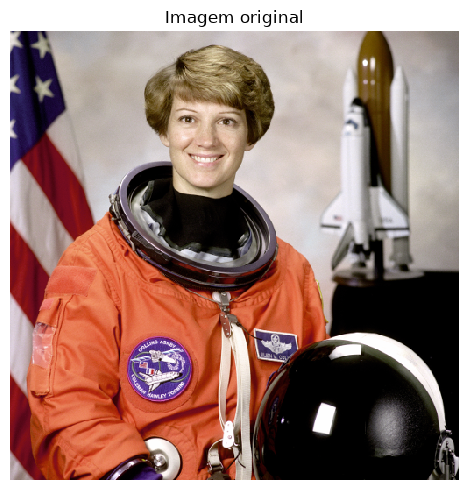

In [3]:
import os
import urllib.request

CAMINHO_IMAGEM = "imagem.png"
URL_IMAGEM = "https://raw.githubusercontent.com/scikit-image/scikit-image/v0.24.0/skimage/data/astronaut.png"

if not os.path.exists(CAMINHO_IMAGEM):
    urllib.request.urlretrieve(URL_IMAGEM, CAMINHO_IMAGEM)

original = Image.open(CAMINHO_IMAGEM).convert("RGB")
original.thumbnail((512, 512))

print("Tamanho (largura x altura):", original.size)
mostrar([np.asarray(original)], ["Imagem original"])

### 2.2 Convertendo para escala de cinza

Cada pixel colorido tem três canais (R, G, B). Para obter a intensidade, não fazemos uma média simples: o olho humano é mais sensível ao verde e menos ao azul. Por isso usamos a soma ponderada da recomendação ITU-R BT.601:

$$Y = 0{,}299\,R + 0{,}587\,G + 0{,}114\,B$$

Guardamos o resultado como `float`, porque o dithering vai somar frações de erro nos pixels e não queremos perder precisão com arredondamentos de inteiros no meio do caminho.

Formato da matriz: (512, 512)
Intensidade mínima: 0.0 | máxima: 255.0


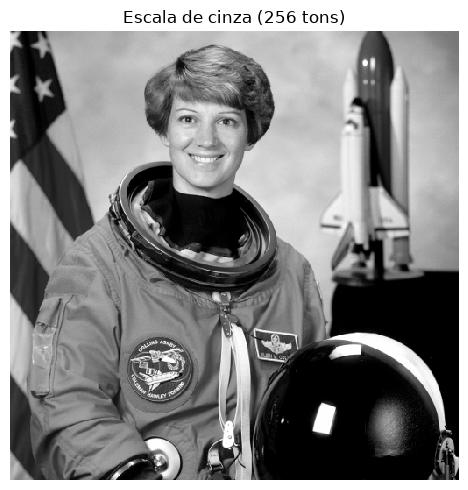

In [4]:
rgb = np.asarray(original, dtype=np.float64)
cinza = 0.299 * rgb[:, :, 0] + 0.587 * rgb[:, :, 1] + 0.114 * rgb[:, :, 2]

print("Formato da matriz:", cinza.shape)
print(f"Intensidade mínima: {cinza.min():.1f} | máxima: {cinza.max():.1f}")
mostrar([cinza], ["Escala de cinza (256 tons)"])

### 2.3 Quantização e limiarização simples

Primeiro, a função de quantização da Seção 1.1. O `np.clip` garante que o resultado fique sempre dentro dos níveis válidos — isso vai ser importante no dithering, porque um pixel pode passar de 255 ou ficar abaixo de 0 depois de receber erro dos vizinhos.

A limiarização é o caso de 2 níveis: cada pixel vira 0 ou 255 dependendo de estar abaixo ou acima do limiar.

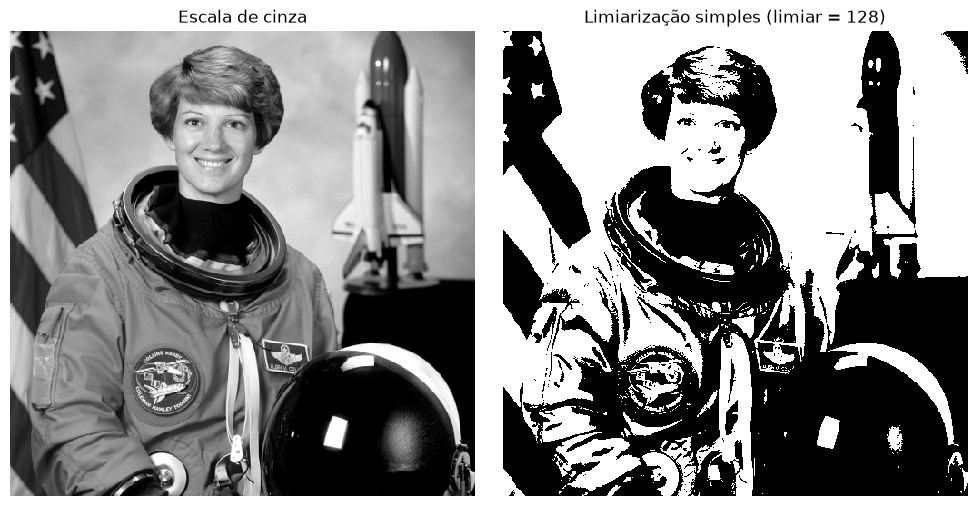

In [5]:
def quantizar(valor, niveis):
    passo = 255 / (niveis - 1)
    return np.clip(np.round(valor / passo), 0, niveis - 1) * passo


def limiarizar(imagem, limiar=128):
    return np.where(imagem >= limiar, 255, 0)


binaria_limiar = limiarizar(cinza)
mostrar([cinza, binaria_limiar], ["Escala de cinza", "Limiarização simples (limiar = 128)"])

Repare no que acontece: as áreas de cinza médio viram manchas inteiras de preto ou de branco. Sombras suaves e texturas desaparecem, e só sobram os contornos de maior contraste. É exatamente o erro de quantização sendo descartado.

### 2.4 Implementando o Floyd-Steinberg

A implementação segue ao pé da letra os passos da Seção 1.4. Os `if` cuidam das bordas: na última coluna não existe vizinho à direita, na primeira coluna não existe vizinho abaixo à esquerda, e na última linha não há ninguém embaixo. Nesses casos aquela parcela do erro é simplesmente descartada.

O parâmetro `niveis` deixa a mesma função servir tanto para preto e branco (`niveis=2`) quanto para mais tons. No final usamos `np.round` antes de converter para `uint8`: a conversão direta trunca a parte decimal (um nível como 145,7 viraria 145 em vez de 146).

In [6]:
def floyd_steinberg(imagem, niveis=2):
    img = imagem.astype(np.float64).copy()
    altura, largura = img.shape

    for y in range(altura):
        for x in range(largura):
            antigo = img[y, x]
            novo = quantizar(antigo, niveis)
            img[y, x] = novo
            erro = antigo - novo

            if x + 1 < largura:
                img[y, x + 1] += erro * 7 / 16
            if y + 1 < altura:
                if x > 0:
                    img[y + 1, x - 1] += erro * 3 / 16
                img[y + 1, x] += erro * 5 / 16
                if x + 1 < largura:
                    img[y + 1, x + 1] += erro * 1 / 16

    return np.round(img).astype(np.uint8)

### 2.5 Comparando os resultados

Agora as três versões lado a lado. A limiarização e o Floyd-Steinberg usam **exatamente os mesmos dois tons** (preto e branco) — a única diferença é o que cada método faz com o erro.

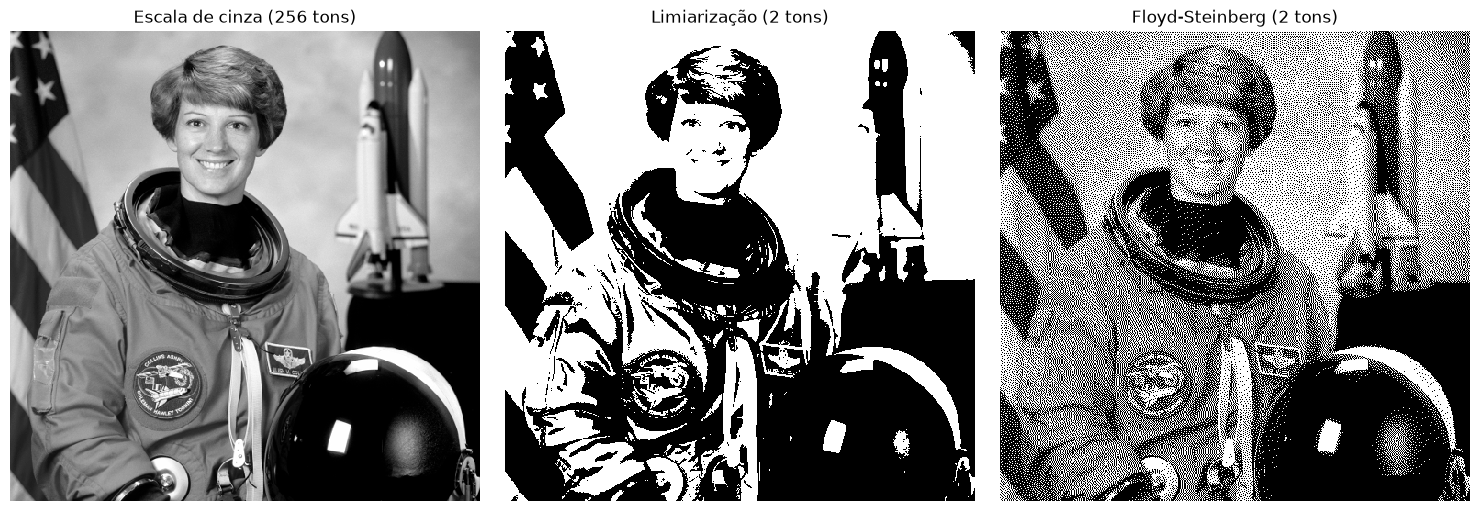

In [7]:
binaria_fs = floyd_steinberg(cinza, niveis=2)

mostrar(
    [cinza, binaria_limiar, binaria_fs],
    ["Escala de cinza (256 tons)", "Limiarização (2 tons)", "Floyd-Steinberg (2 tons)"],
)

Com o dithering, os tons intermediários voltam a aparecer: regiões cinzas viram uma mistura de pontos pretos e brancos cuja densidade acompanha a intensidade original. As sombras e os degradês ficam reconhecíveis, mesmo sem nenhum pixel cinza na imagem.

Ampliando um pedaço da imagem dá para ver o que realmente está acontecendo nos pixels:

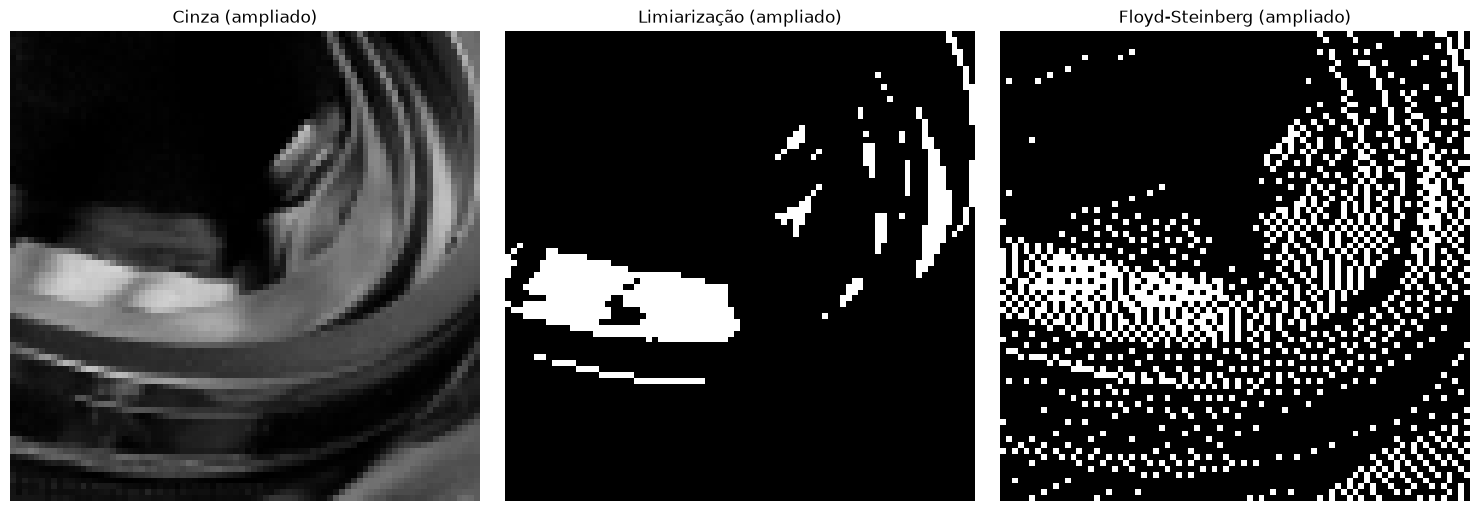

In [8]:
altura, largura = cinza.shape
cy, cx = altura // 2, largura // 2
recorte = (slice(cy - 40, cy + 40), slice(cx - 40, cx + 40))

mostrar(
    [cinza[recorte], binaria_limiar[recorte], binaria_fs[recorte]],
    ["Cinza (ampliado)", "Limiarização (ampliado)", "Floyd-Steinberg (ampliado)"],
)

### 2.6 Diferentes níveis de quantização

O mesmo raciocínio vale quando permitimos mais tons. Abaixo comparamos, para 2, 4 e 8 níveis de cinza, a **quantização direta** (arredonda para o nível mais próximo e descarta o erro) com o **Floyd-Steinberg** usando os mesmos níveis.

Essa célula demora um pouco mais, porque roda o dithering três vezes.

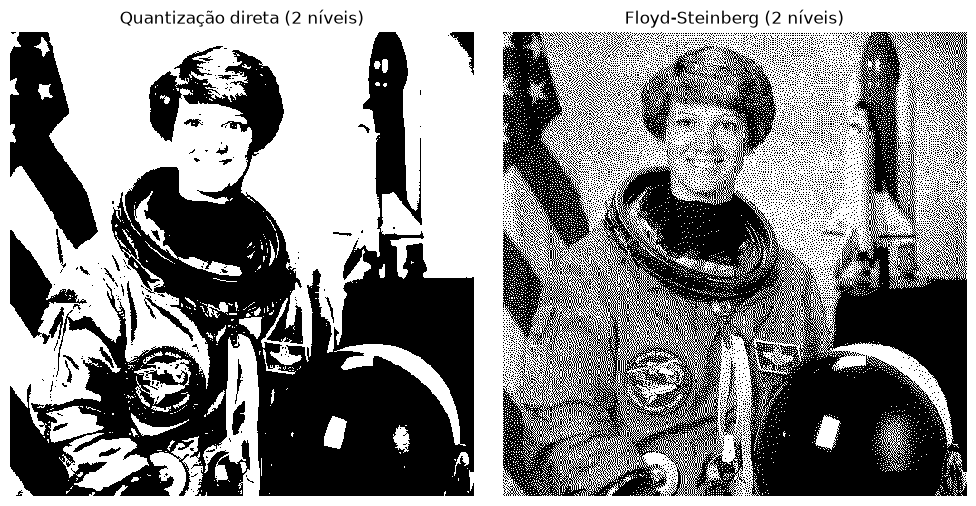

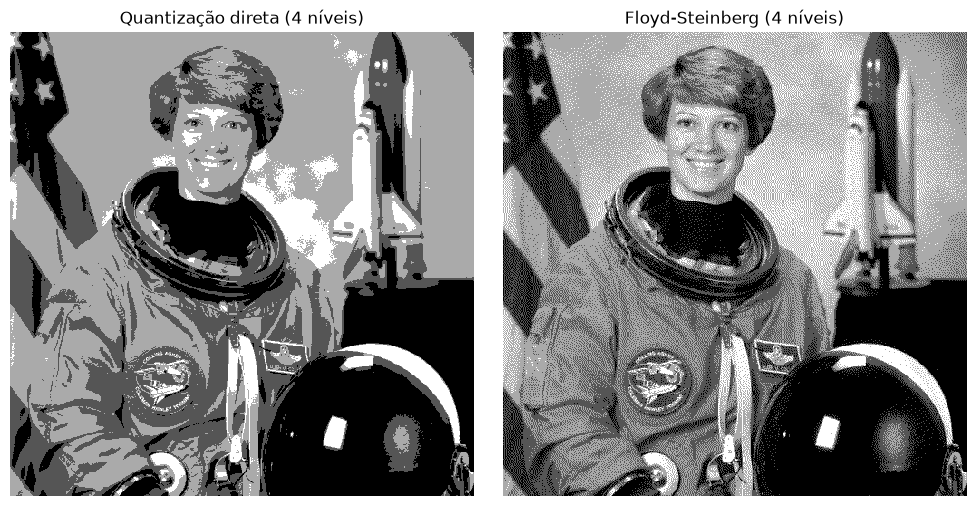

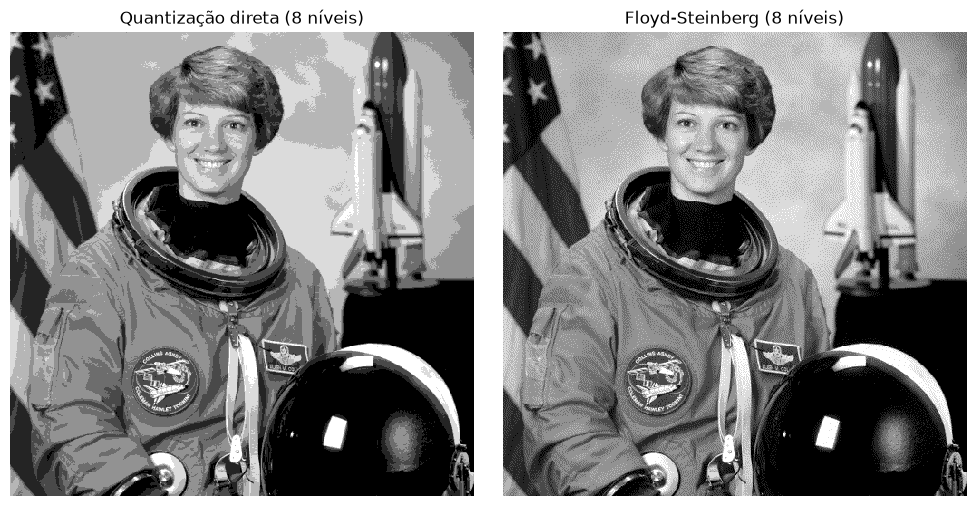

In [9]:
for niveis in [2, 4, 8]:
    direta = quantizar(cinza, niveis)
    com_dithering = floyd_steinberg(cinza, niveis)
    mostrar(
        [direta, com_dithering],
        [f"Quantização direta ({niveis} níveis)", f"Floyd-Steinberg ({niveis} níveis)"],
    )

O que dá para notar:

- Na **quantização direta**, aparecem faixas bem marcadas onde havia degradê (*banding*). Com 8 níveis já melhora, mas as "curvas de nível" ainda são visíveis em regiões suaves.
- Com o **Floyd-Steinberg**, as transições entre níveis são misturadas por pontos, e as faixas praticamente somem. Com 4 níveis o resultado já fica bem próximo da imagem em 256 tons, e com 8 a diferença é difícil de perceber a olho nu.
- Quanto mais níveis, menor o erro de cada pixel, então o "ruído" do dithering fica cada vez mais discreto.

### 2.7 Artefatos em um degradê

Fotos reais têm muita textura, o que esconde parte dos defeitos. Um degradê horizontal de 0 a 255 deixa tudo mais evidente, então vale a pena testar os métodos nele também.

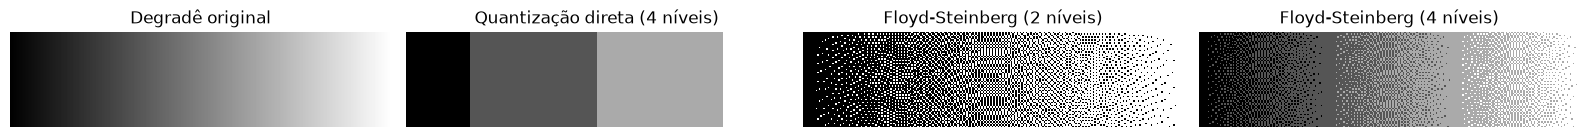

In [10]:
degrade = np.tile(np.linspace(0, 255, 256), (64, 1))

mostrar(
    [degrade, quantizar(degrade, 4), floyd_steinberg(degrade, 2), floyd_steinberg(degrade, 4)],
    ["Degradê original", "Quantização direta (4 níveis)", "Floyd-Steinberg (2 níveis)", "Floyd-Steinberg (4 níveis)"],
    tamanho=4,
)

A quantização direta transforma o degradê em quatro degraus. O Floyd-Steinberg reconstrói a transição contínua, mas olhando de perto aparecem padrões característicos do método: perto dos extremos, os pontos isolados formam pequenas sequências alinhadas (os chamados *worms*, "minhocas"), e em alguns tons específicos surgem texturas regulares, quase em xadrez ou em diagonal.

### 2.8 Dithering em imagens coloridas

A proposta do dithering não se limita à escala de cinza. O jeito mais simples de levar o Floyd-Steinberg para cores é tratar cada canal (R, G e B) como uma imagem em cinza independente e aplicar a mesma função em cada um.

Com 2 níveis por canal, cada pixel só pode assumir $2^3 = 8$ cores: preto, branco, vermelho, verde, azul, ciano, magenta e amarelo. Vamos comparar a quantização direta com o dithering usando essa mesma paleta de 8 cores.

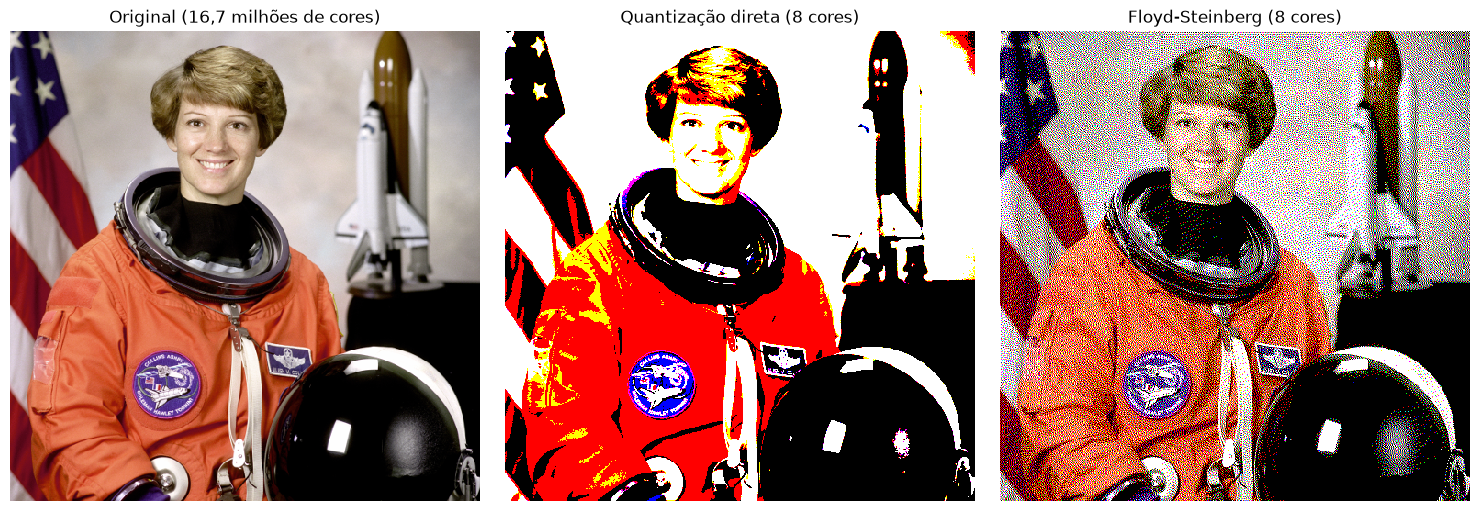

In [11]:
def floyd_steinberg_colorido(imagem_rgb, niveis=2):
    canais = [floyd_steinberg(imagem_rgb[:, :, c], niveis) for c in range(3)]
    return np.stack(canais, axis=2)


colorida_direta = np.round(quantizar(rgb, 2)).astype(np.uint8)
colorida_fs = floyd_steinberg_colorido(rgb, 2)

mostrar(
    [np.asarray(original), colorida_direta, colorida_fs],
    ["Original (16,7 milhões de cores)", "Quantização direta (8 cores)", "Floyd-Steinberg (8 cores)"],
)

Na quantização direta, a imagem vira grandes áreas chapadas de cores saturadas, e os tons de pele, as sombras e o fundo se perdem. Com o Floyd-Steinberg, a mistura de pontos das 8 cores básicas recria tons que não existem na paleta: o olho combina, por exemplo, pontos vermelhos, amarelos e brancos e percebe o laranja do traje ou tons de pele.

Essa abordagem por canal é simples, mas não é a única: métodos mais elaborados escolhem a cor mais próxima numa paleta arbitrária (por exemplo, as 256 cores de um GIF) e difundem o erro como um vetor RGB. A ideia central, porém, é exatamente a mesma que vimos em escala de cinza.

## 3. Discussão: vantagens, limitações e artefatos

**Vantagens**
- **Preserva a percepção de tons** usando poucos níveis, porque o erro não é descartado: a média local da imagem se mantém próxima da original.
- **Simples de implementar**: uma única passada pela imagem, quatro vizinhos e pesos fixos.
- **Elimina o *banding***: degradês continuam parecendo degradês, mesmo em preto e branco.
- Preserva bem bordas e detalhes finos, ao contrário de métodos de pontilhado com padrão fixo, que costumam deixar a imagem com cara de "grade".

**Limitações**
- **É sequencial**: cada pixel depende do erro acumulado dos anteriores, então não dá para processar os pixels de forma independente. Isso dificulta paralelizar o algoritmo (em GPU, por exemplo).
- **Introduz ruído** em regiões que eram lisas. Visto de perto, a imagem fica granulada.
- **Depende da escala de visualização**: o efeito funciona porque o olho faz a média dos pontos. Se a imagem for ampliada, os pontos ficam evidentes; se for reduzida com interpolação, o padrão pode gerar efeitos de *moiré*.
- É **sensível a pequenas mudanças**: alterar um único pixel muda o erro propagado e pode alterar o padrão de pontos de toda a região seguinte. Em vídeo, isso causa "cintilação" entre quadros.

**Artefatos**
- ***Worms***: sequências de pontos alinhados que aparecem em tons muito claros ou muito escuros.
- **Texturas direcionais**: como o erro sempre anda para a direita e para baixo, surgem padrões levemente diagonais em áreas uniformes. Uma variação conhecida para reduzir isso é a varredura em serpentina (alternar o sentido a cada linha).
- **Padrões regulares** em alguns tons intermediários (por exemplo, perto de 50% de cinza, onde aparece um xadrez quase perfeito).

Mesmo com esses defeitos, o Floyd-Steinberg continua sendo a referência quando se fala em dithering: é rápido, simples e entrega um resultado visualmente muito superior à quantização direta. Ele mostra bem uma ideia central da Computação Visual: o que importa não é só o valor exato de cada pixel, mas como o conjunto é percebido pelo olho humano.

## Referências

- FLOYD, R. W.; STEINBERG, L. An adaptive algorithm for spatial greyscale. *Proceedings of the Society for Information Display*, v. 17, n. 2, p. 75–77, 1976.
- ULICHNEY, R. *Digital Halftoning*. Cambridge: MIT Press, 1987.
- GONZALEZ, R. C.; WOODS, R. E. *Processamento Digital de Imagens*. 3. ed. São Paulo: Pearson Prentice Hall, 2010.
- INTERNATIONAL TELECOMMUNICATION UNION. *Recommendation ITU-R BT.601: Studio encoding parameters of digital television for standard 4:3 and wide-screen 16:9 aspect ratios*. Genebra: ITU, 2011.
- NASA. *Astronaut Eileen Collins*. Fotografia em domínio público, distribuída como imagem de exemplo (`astronaut.png`) pela biblioteca scikit-image. Disponível em: https://github.com/scikit-image/scikit-image/blob/v0.24.0/skimage/data/astronaut.png
- NumPy. Documentação oficial. Disponível em: https://numpy.org/doc/
- Pillow. Documentação oficial. Disponível em: https://pillow.readthedocs.io/